# 미세먼지와 지하철 이용객: 금요일 효과 & 시차 효과 검증

**검증할 질문**
1. 금요일에는 미세먼지가 심해도 지하철 이용객이 줄어들지 않을까?
2. 미세먼지가 심해진 **당일**에 이용객이 줄어들까, 아니면 **다음 날**에 변화가 나타날까?

## 0. 환경 설정

In [1]:
import os, sys, zipfile, unicodedata, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules

def set_korean_font():
    cands = ["NanumGothic", "Malgun Gothic", "AppleGothic", "NanumBarunGothic", "Noto Sans CJK KR", "Noto Sans CJK JP"]
    def pick():
        names = {f.name for f in fm.fontManager.ttflist}
        return next((c for c in cands if c in names), None)
    font = pick()
    if font is None:
        for f in fm.findSystemFonts(fontpaths=["/usr/share/fonts/opentype/noto"]):
            fm.fontManager.addfont(f)
        font = pick()
    if font is None and IN_COLAB:
        subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-nanum"], check=False)
        for f in fm.findSystemFonts(fontpaths=["/usr/share/fonts/truetype/nanum"]):
            fm.fontManager.addfont(f)
        font = pick()
    if font:
        plt.rcParams["font.family"] = font
    plt.rcParams["axes.unicode_minus"] = False
    return font

sns.set_style("whitegrid")
print("사용 폰트:", set_korean_font())
plt.rcParams["figure.dpi"] = 110


사용 폰트: NanumGothic


## 1. 데이터 불러오기

In [2]:
ROOT = Path.cwd()
SEARCH_DIRS = [ROOT, ROOT / "rawfiles", Path("/content"), Path("/content/drive/MyDrive"), Path("/mnt/user-data/uploads")]

def nfc(s):
    return unicodedata.normalize("NFC", str(s))

def iter_dirs():
    for d in SEARCH_DIRS:
        if d.is_dir():
            yield d

def find_file(keyword, ext):
    for d in iter_dirs():
        for f in sorted(d.iterdir()):
            if f.is_file() and keyword in nfc(f.name) and f.suffix.lower() == ext:
                return f
    return None

def find_subway_csvs():
    hits = []
    for d in iter_dirs():
        hits.extend(sorted(d.glob("CARD_SUBWAY_MONTH*.csv")))
        hits.extend(sorted(d.glob("**/CARD_SUBWAY_MONTH*.csv")))
    uniq = []
    seen = set()
    for f in hits:
        key = str(f.resolve()) if f.exists() else str(f)
        if key not in seen:
            seen.add(key)
            uniq.append(f)
    return uniq

AIR_PATH = find_file("대기오염도", ".csv")
ZIP_PATH = find_file("rawfiles", ".zip")
subway_csvs = find_subway_csvs()

if AIR_PATH is None and IN_COLAB:
    from google.colab import files
    files.upload()
    AIR_PATH = find_file("대기오염도", ".csv")
    ZIP_PATH = find_file("rawfiles", ".zip")
    subway_csvs = find_subway_csvs()

def read_csv_auto(src):
    for enc in ("utf-8-sig", "utf-8", "cp949"):
        try:
            buf = src() if callable(src) else src
            return pd.read_csv(buf, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError("CSV 인코딩을 읽지 못했습니다.")

if subway_csvs:
    print("지하철 CSV:", [f.name for f in subway_csvs])
    subway = pd.concat([read_csv_auto(f) for f in subway_csvs], ignore_index=True)
elif ZIP_PATH is not None:
    print("지하철 ZIP:", ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH) as zf:
        names = sorted(n for n in zf.namelist() if "CARD_SUBWAY_MONTH" in n and n.endswith(".csv"))
        print("읽은 지하철 파일:", [os.path.basename(n) for n in names])
        subway = pd.concat([read_csv_auto(lambda n=n: zf.open(n)) for n in names], ignore_index=True)
else:
    raise FileNotFoundError("CARD_SUBWAY_MONTH csv 또는 rawfiles.zip 을 노트북과 같은 폴더, 또는 rawfiles 폴더에 두세요.")

if AIR_PATH is None:
    raise FileNotFoundError("일별평균대기오염도 csv 를 노트북과 같은 폴더, 또는 rawfiles 폴더에 두세요.")

print("대기오염 CSV:", AIR_PATH)
air = read_csv_auto(AIR_PATH)

print("\n지하철:", subway.shape, "| 대기오염:", air.shape)
display(subway.head(3))
display(air.head(3))


지하철 CSV: ['CARD_SUBWAY_MONTH_201901.csv', 'CARD_SUBWAY_MONTH_201902.csv', 'CARD_SUBWAY_MONTH_201903.csv', 'CARD_SUBWAY_MONTH_201904.csv', 'CARD_SUBWAY_MONTH_201905.csv', 'CARD_SUBWAY_MONTH_201906.csv']
대기오염 CSV: c:\Users\LG\Desktop\AI+X\subway_project\teamproject\rawfiles\일별평균대기오염도_2019.csv

지하철: (107028, 6) | 대기오염: (17745, 8)


,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
0,20190101,2호선,을지로4가,3862.0,3728.0,20190104
1,20190101,3호선,을지로3가,8104.0,7554.0,20190104
2,20190101,2호선,을지로입구,22478.0,21330.0,20190104


,측정일시,측정소명,이산화질소농도(ppm),오존농도(ppm),일산화탄소농도(ppm),아황산가스농도(ppm),미세먼지농도(㎍/㎥),초미세먼지농도(㎍/㎥)
0,20190101,강남구,0.027,0.013,0.6,0.005,35.0,30.0
1,20190101,강남대로,0.040,0.010,0.9,0.004,38.0,26.0
2,20190101,강동구,0.037,0.012,0.7,0.005,40.0,30.0


## 2. 전처리

### 2-1. 일별 데이터 만들기
- **지하철**: 전 역의 `승차+하차`를 하루 단위로 합산 → 하루 총 이용객 (과제 기준인 *승하차총승객수*)
- **미세먼지**: 서울 50개 측정소 평균 (측정소별 결측은 자동 제외하고 평균)

In [3]:
subway["날짜"] = pd.to_datetime(subway["사용일자"].astype(str), format="%Y%m%d")
subway["승하차"] = subway["승차총승객수"] + subway["하차총승객수"]
daily = subway.groupby("날짜")["승하차"].sum()

def col_like(df, *parts):
    for c in df.columns:
        if all(p in str(c) for p in parts):
            return c
    raise KeyError(parts)

air["날짜"] = pd.to_datetime(air["측정일시"].astype(str), format="%Y%m%d")
air = air.rename(columns={col_like(air, "미세먼지"): "PM10", col_like(air, "초미세"): "PM25"})
air = air[air["날짜"].between("2019-01-01", "2019-06-30")]
dust = air.groupby("날짜")[["PM10", "PM25"]].mean()

df = daily.to_frame().join(dust, how="left")

df["요일"] = df.index.dayofweek
df["요일명"] = df["요일"].map(dict(enumerate("월화수목금토일")))
assert df.loc["2019-01-01", "요일명"] == "화", "2019-01-01은 화요일이어야 합니다"

print("기간:", df.index.min().date(), "~", df.index.max().date(), f"({len(df)}일)")
print("결측:", df[["승하차", "PM10", "PM25"]].isna().sum().to_dict())
display(df.head())


기간: 2019-01-01 ~ 2019-06-30 (181일)
결측: {'승하차': 0, 'PM10': 0, 'PM25': 0}


,승하차,PM10,PM25,요일,요일명
날짜,,,,,
2019-01-01,6813453.0,37.043478,23.891304,1,화
2019-01-02,15214002.0,35.086957,21.804348,2,수
2019-01-03,15716213.0,39.717391,23.195652,3,목
2019-01-04,16509281.0,58.847826,40.195652,4,금
2019-01-05,12092335.0,62.847826,38.782609,5,토


### 2-2. 데이터 품질 확인
이상값이 분석 결과를 뒤집을 수 있으니 중복·결측·측정소 수를 먼저 확인합니다.

In [4]:
key = ["사용일자", "노선명", "역명"]
print("완전히 동일한 행:", subway.duplicated().sum(), "개")
print("같은 (날짜·노선·역명) 키를 가진 행:", subway.duplicated(key).sum(), "개 → 값이 서로 다른 별개 행(같은 이름의 역이 한 노선에 여러 번 등장)이라 중복 집계가 아님. 그대로 합산")
print("날짜별 행 수:", subway.groupby("사용일자").size().min(), "~", subway.groupby("사용일자").size().max(), "(거의 일정 → 특정 날짜만 누락/중복된 일 없음)")
print("음수 승객수:", int((subway[["승차총승객수", "하차총승객수"]] < 0).sum().sum()))
n_st = air.groupby("날짜")[["PM10", "PM25"]].count()
print(f"하루에 측정값이 있는 측정소 수 → PM10 최소 {n_st.PM10.min()}개, PM2.5 최소 {n_st.PM25.min()}개 (총 50개 중)")
print("서울 평균 PM2.5 요약:"); display(df["PM25"].describe().round(1).to_frame().T)

완전히 동일한 행: 0 개
같은 (날짜·노선·역명) 키를 가진 행: 14899 개 → 값이 서로 다른 별개 행(같은 이름의 역이 한 노선에 여러 번 등장)이라 중복 집계가 아님. 그대로 합산
날짜별 행 수: 588 ~ 594 (거의 일정 → 특정 날짜만 누락/중복된 일 없음)
음수 승객수: 0
하루에 측정값이 있는 측정소 수 → PM10 최소 44개, PM2.5 최소 43개 (총 50개 중)
서울 평균 PM2.5 요약:


,count,mean,std,min,25%,50%,75%,max
PM25,181.0,31.0,20.8,5.0,19.3,24.2,36.9,135.5


### 2-3. 연휴 제외 + 요일 효과 제거 → **이용지수** 만들기

지하철 이용객은 **요일(평일 vs 주말)** 과 **연휴**의 영향이 미세먼지보다 훨씬 큽니다.
그래서 그냥 이용객 수를 비교하면 "금요일은 원래 많다" 같은 효과가 섞입니다.

- **연휴/징검다리 구간 제외**: 설 연휴·삼일절·근로자의 날~어린이날 연휴·석가탄신일·현충일 전후
  (특히 **3/1(금)은 삼일절이면서 미세먼지가 심했던 날**이라 제외하지 않으면 '금요일 효과'가 왜곡됩니다)
- **이용지수 = 그날 이용객 ÷ 같은 요일의 앞뒤 2주(자기 자신 제외) 중앙값**
  → 1.00이면 평소 같은 요일 수준, 0.97이면 평소보다 3% 적음

In [5]:
HOLIDAY_WINDOWS = [
    ("2019-01-01", "2019-01-01", "신정"),
    ("2019-02-01", "2019-02-10", "설 연휴 전후"),
    ("2019-03-01", "2019-03-03", "삼일절 연휴"),
    ("2019-04-30", "2019-05-06", "근로자의 날~어린이날 연휴"),
    ("2019-05-12", "2019-05-12", "석가탄신일"),
    ("2019-06-06", "2019-06-09", "현충일 연휴"),
]
df["연휴"] = False
for s, e, _ in HOLIDAY_WINDOWS:
    df.loc[s:e, "연휴"] = True
print(f"제외한 연휴 일수: {df['연휴'].sum()}일 → 분석 대상 {(~df['연휴']).sum()}일")

def neighbor_baseline(s, k=2):
    nb = pd.concat([s.shift(j) for j in list(range(-k, 0)) + list(range(1, k + 1))], axis=1)
    return nb.median(axis=1, skipna=True).where(nb.notna().sum(axis=1) >= 2)

df["기준선"] = np.nan
for d in range(7):
    x = df.loc[(df["요일"] == d) & (~df["연휴"]), "승하차"]
    df.loc[x.index, "기준선"] = neighbor_baseline(x)
df["이용지수"] = df["승하차"] / df["기준선"]

# PM2.5 좋음≤15 / 보통≤35 / 나쁨≤75 / 매우나쁨≥76
df["PM25등급"] = pd.cut(df["PM25"].round(), [-1, 15, 35, 75, 1e9], labels=["좋음", "보통", "나쁨", "매우나쁨"])
df["PM25나쁨"] = df["PM25"].round() >= 36
df["PM10나쁨"] = df["PM10"].round() >= 81

df["그룹"] = np.select([df["요일"] <= 3, df["요일"] == 4], ["월~목", "금"], "주말")
an = df[~df["연휴"]].dropna(subset=["이용지수", "PM25"]).copy()
print("분석용 데이터:", an.shape)


제외한 연휴 일수: 26일 → 분석 대상 155일
분석용 데이터: (155, 12)


## 3. 탐색적 분석 (EDA)

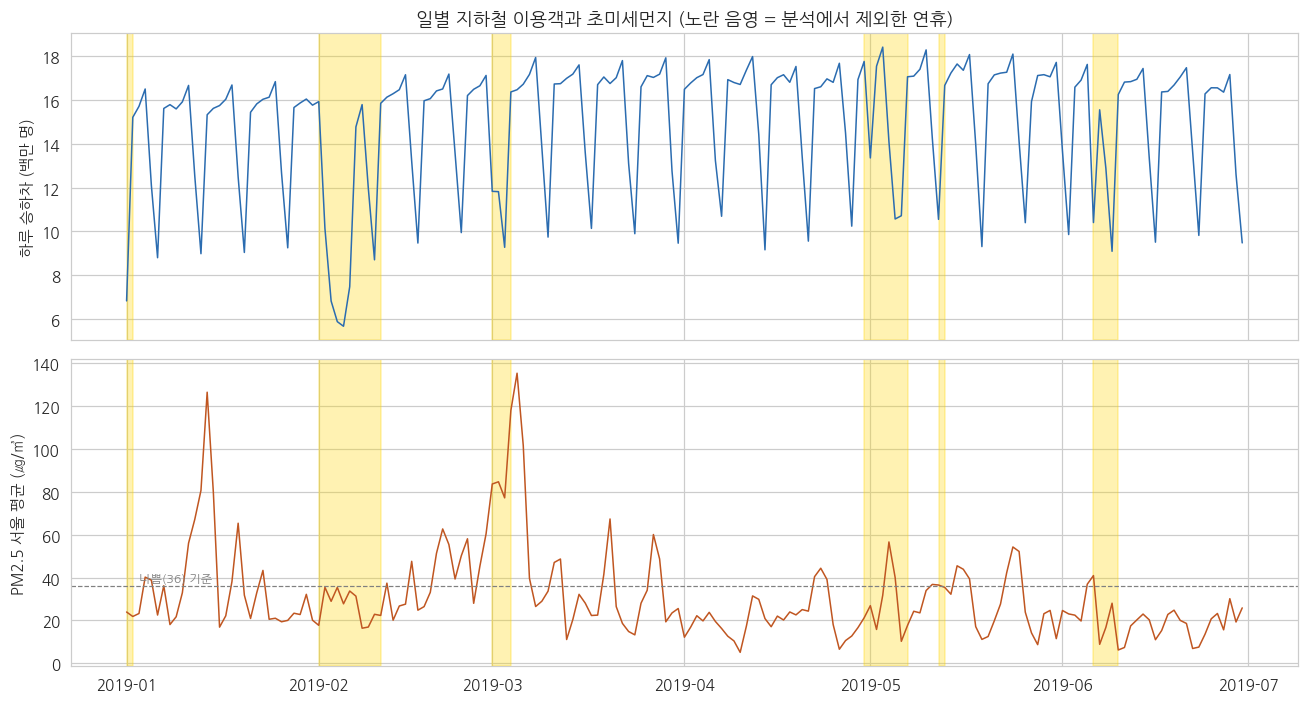

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
axes[0].plot(df.index, df["승하차"] / 1e6, color="#2b6cb0", lw=1)
axes[0].set_ylabel("하루 승하차 (백만 명)")
axes[1].plot(df.index, df["PM25"], color="#c05621", lw=1)
axes[1].axhline(36, color="gray", ls="--", lw=0.8); axes[1].text(df.index[2], 38, "나쁨(36) 기준", fontsize=8, color="gray")
axes[1].set_ylabel("PM2.5 서울 평균 (㎍/㎥)")
for ax in axes:
    for s, e, _ in HOLIDAY_WINDOWS:
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e) + pd.Timedelta(days=1), color="gold", alpha=0.3)
axes[0].set_title("일별 지하철 이용객과 초미세먼지 (노란 음영 = 분석에서 제외한 연휴)")
plt.tight_layout(); plt.show()

**위 그래프에서 볼 것**: 이용객은 일주일 단위의 뚜렷한 리듬(평일 높고 주말 낮음)이 지배적이라, 미세먼지가 심한 날(2월 말, 3월 초 등)의 영향이 눈으로는 보이지 않습니다. 그래서 **이용지수**로 요일 효과를 걷어낸 뒤 비교합니다.

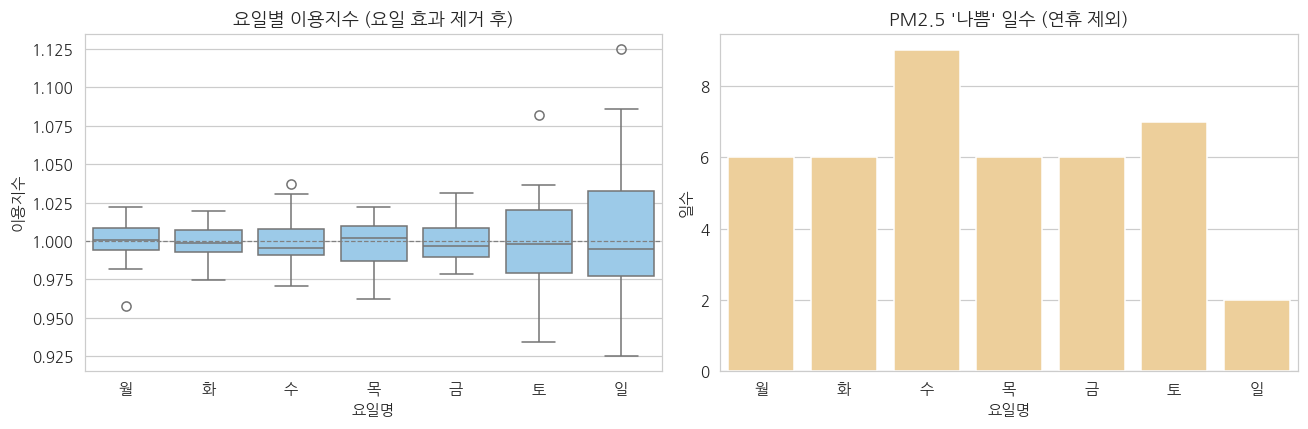

,분석일수,PM25_나쁨일수,PM10_나쁨일수
그룹,,,
월~목,93,27,12
금,21,6,1
주말,41,9,3


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = list("월화수목금토일")
sns.boxplot(data=an, x="요일명", y="이용지수", order=order, ax=axes[0], color="#90cdf4")
axes[0].axhline(1, color="gray", ls="--", lw=0.8); axes[0].set_title("요일별 이용지수 (요일 효과 제거 후)")
sns.countplot(data=an[an["PM25나쁨"]], x="요일명", order=order, ax=axes[1], color="#fbd38d")
axes[1].set_title("PM2.5 '나쁨' 일수 (연휴 제외)"); axes[1].set_ylabel("일수")
plt.tight_layout(); plt.show()

tab = an.groupby("그룹").agg(분석일수=("이용지수", "size"), PM25_나쁨일수=("PM25나쁨", "sum"), PM10_나쁨일수=("PM10나쁨", "sum"))
display(tab.loc[["월~목", "금", "주말"]])

> ⚠️ **표본 크기 주의**: 금요일의 '나쁨' 일수가 매우 적습니다. 효과가 아주 크지 않으면 통계적으로 잡아내기 어렵다는 뜻이므로, 아래 결과는 *"차이가 없다"* 가 아니라 *"차이가 있다는 증거를 찾지 못했다"* 로 읽어야 합니다.

## 4. 질문 1: 금요일에는 미세먼지가 심해도 이용객이 줄지 않을까?

**쪼개서 보면**
- (a) 금요일에 미세먼지 '나쁨'인 날의 이용지수가 그렇지 않은 날보다 낮은가?
- (b) 그 차이가 월~목과 비교해서 다른가? (= 금요일만의 특별한 효과가 있는가?)

**가설 (그룹별 Mann-Whitney U)**
- H0: 미세먼지 '나쁨' 날과 아닌 날의 이용지수 분포에 차이가 없다
- H1: 차이가 있다

In [8]:
def compare_group(g, flag="PM25나쁨", dust_col="PM25", n_boot=5000, seed=0):
    bad, ok = g.loc[g[flag], "이용지수"], g.loc[~g[flag], "이용지수"]
    rng = np.random.default_rng(seed)
    diffs = [np.median(rng.choice(bad, len(bad))) - np.median(rng.choice(ok, len(ok))) for _ in range(n_boot)]
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    rho, p_rho = stats.spearmanr(g[dust_col], g["이용지수"])
    return {
        "n(나쁨)": len(bad), "n(그외)": len(ok),
        "중앙값 차이(%p)": round((bad.median() - ok.median()) * 100, 2),
        "95% CI(%p)": f"[{lo*100:.2f}, {hi*100:.2f}]",
        "정규성 Shapiro p": round(stats.shapiro(g["이용지수"]).pvalue, 3),
        "Welch t p": round(stats.ttest_ind(bad, ok, equal_var=False).pvalue, 3),
        "Mann-Whitney U p": round(stats.mannwhitneyu(bad, ok, alternative="two-sided").pvalue, 3),
        "Spearman ρ": round(rho, 3), "Spearman p": round(p_rho, 3),
    }

res1 = pd.DataFrame({k: compare_group(an[an["그룹"] == k]) for k in ["월~목", "금", "주말"]}).T
display(res1)


,n(나쁨),n(그외),중앙값 차이(%p),95% CI(%p),정규성 Shapiro p,Welch t p,Mann-Whitney U p,Spearman ρ,Spearman p
월~목,27,66,0.46,"[-0.42, 1.29]",0.621,0.16,0.269,0.029,0.786
금,6,15,0.06,"[-1.28, 1.43]",0.59,0.967,0.91,0.182,0.43
주말,9,32,1.56,"[-0.74, 3.32]",0.107,0.546,0.337,0.083,0.606


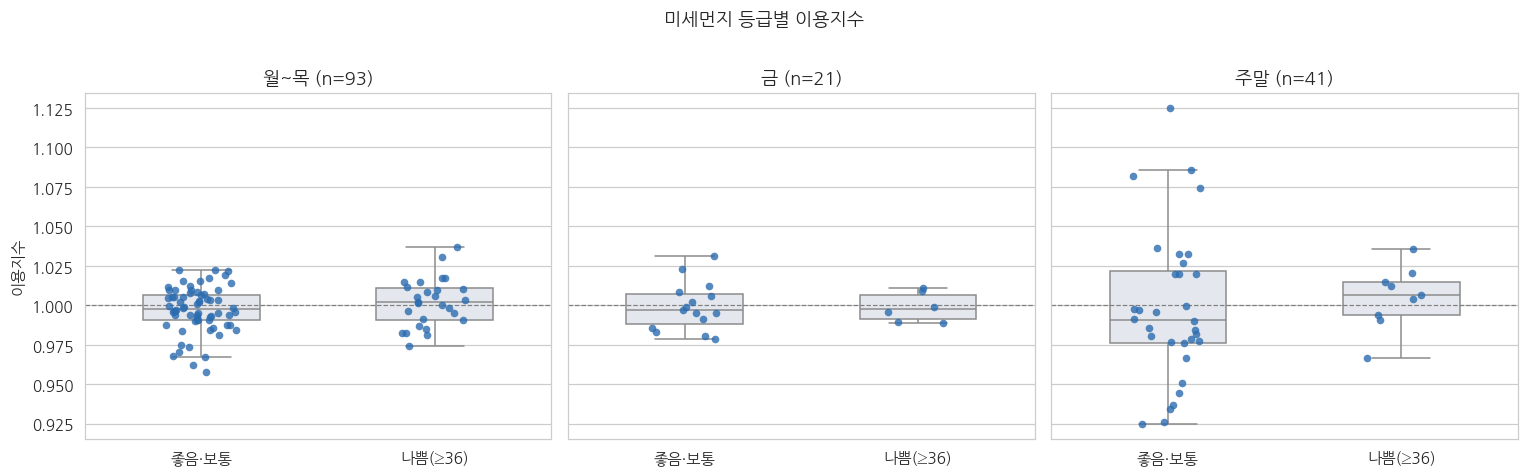

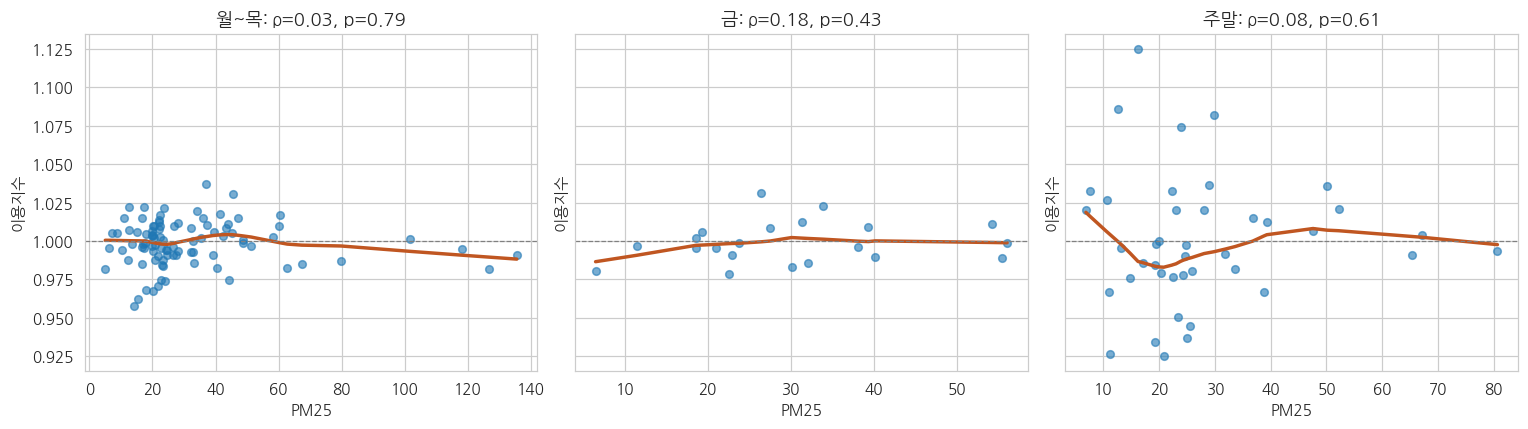

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, k in zip(axes, ["월~목", "금", "주말"]):
    g = an[an["그룹"] == k]
    sns.boxplot(data=g, x="PM25나쁨", y="이용지수", order=[False, True], ax=ax, color="#e2e8f0", fliersize=0, width=0.5)
    sns.stripplot(data=g, x="PM25나쁨", y="이용지수", order=[False, True], ax=ax, alpha=0.8, jitter=0.15, color="#2b6cb0")
    ax.axhline(1, color="gray", ls="--", lw=0.8)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["좋음·보통", "나쁨(≥36)"])
    ax.set_xlabel("")
    ax.set_title(f"{k} (n={len(g)})")
axes[0].set_ylabel("이용지수")
plt.suptitle("미세먼지 등급별 이용지수", y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, k in zip(axes, ["월~목", "금", "주말"]):
    g = an[an["그룹"] == k]
    try:
        sns.regplot(data=g, x="PM25", y="이용지수", ax=ax, scatter_kws=dict(alpha=0.6, s=25), line_kws=dict(color="#c05621"), lowess=True)
    except Exception:
        sns.regplot(data=g, x="PM25", y="이용지수", ax=ax, scatter_kws=dict(alpha=0.6, s=25), line_kws=dict(color="#c05621"))
    rho, p = stats.spearmanr(g["PM25"], g["이용지수"])
    ax.set_title(f"{k}: ρ={rho:.2f}, p={p:.2f}")
    ax.axhline(1, color="gray", ls="--", lw=0.8)
axes[0].set_ylabel("이용지수")
plt.tight_layout()
plt.show()


### (b) 금요일이 월~목과 *다른가*? — 차이의 차이(Difference-in-differences) 검정

`D = (금요일의 나쁨−그외 중앙값 차이) − (월~목의 나쁨−그외 중앙값 차이)`

D≠0이면 "금요일은 미세먼지에 대한 반응이 다르다"는 뜻입니다. 분포 가정 없이 **순열검정**(나쁨 라벨을 그룹 안에서 섞기)으로 p값을 구하고, 보조로 회귀(상호작용항)도 확인합니다.

In [10]:
def med_gap(g, flag="PM25나쁨"):
    return g.loc[g[flag], "이용지수"].median() - g.loc[~g[flag], "이용지수"].median()

def did_permutation(a, b, flag="PM25나쁨", n_perm=10000, seed=0):
    rng = np.random.default_rng(seed)
    obs = med_gap(b, flag) - med_gap(a, flag)
    cnt = 0
    for _ in range(n_perm):
        a2, b2 = a.copy(), b.copy()
        a2[flag] = rng.permutation(a2[flag].values)
        b2[flag] = rng.permutation(b2[flag].values)
        cnt += abs(med_gap(b2, flag) - med_gap(a2, flag)) >= abs(obs)
    return obs, (cnt + 1) / (n_perm + 1)

obs, p_perm = did_permutation(an[an["그룹"] == "월~목"], an[an["그룹"] == "금"])
print(f"차이의 차이 D = {obs*100:.2f}%p  (순열검정 p = {p_perm:.3f})")

try:
    import statsmodels.formula.api as smf
    x = an[an["요일"] <= 4].copy()
    x["금요일"] = (x["요일"] == 4).astype(int)
    fit = smf.ols("이용지수 ~ PM25 * 금요일", data=x).fit(cov_type="HC3")
    print("\n회귀: 이용지수 ~ PM25 × 금요일  (평일만, HC3)")
    display(fit.summary2().tables[1].round(5))
except ImportError:
    print("statsmodels 미설치 → 회귀 생략")


차이의 차이 D = -0.40%p  (순열검정 p = 0.630)

회귀: 이용지수 ~ PM25 × 금요일  (평일만, HC3)


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,0.99904,0.00250,399.70176,0.00000,0.99414,1.00393
PM25,-0.00001,0.00006,-0.23472,0.81442,-0.00012,0.00010
금요일,-0.00481,0.00734,-0.65624,0.51167,-0.01920,0.00957
PM25:금요일,0.00018,0.00021,0.82776,0.40781,-0.00024,0.00060


### 확인용 ①: 미세먼지 등급 4단계 Kruskal-Wallis
'나쁨/아님' 이분법 대신 등급(좋음·보통·나쁨·매우나쁨) 전체로 이용지수가 달라지는지 봅니다 (3개 이상 집단 비교 → 슬라이드의 Kruskal-Wallis).

In [11]:
rows = {}
for k in ["월~목", "금", "주말"]:
    g = an[an["그룹"] == k]
    groups = [v["이용지수"].values for _, v in g.groupby("PM25등급", observed=True) if len(v) > 0]
    n_by = g["PM25등급"].value_counts().reindex(["좋음", "보통", "나쁨", "매우나쁨"]).fillna(0).astype(int).to_dict()
    H, p = stats.kruskal(*groups)
    rows[k] = {"등급별 일수": n_by, "H": round(H, 2), "p": round(p, 3)}
display(pd.DataFrame(rows).T)

,등급별 일수,H,p
월~목,"{'좋음': 12, '보통': 54, '나쁨': 22, '매우나쁨': 5}",6.1,0.107
금,"{'좋음': 2, '보통': 13, '나쁨': 6, '매우나쁨': 0}",1.17,0.558
주말,"{'좋음': 8, '보통': 24, '나쁨': 8, '매우나쁨': 1}",1.36,0.715


### 확인용 ②: 기준을 바꿔도 결론이 같을까? (Robustness)
'나쁨'의 정의(PM2.5≥36 / PM10≥81)를 바꿔도 결과가 유지되는지 확인합니다.

In [12]:
rows = []
for label, flag, dcol in [("PM2.5 나쁨(≥36)", "PM25나쁨", "PM25"), ("PM10 나쁨(≥81)", "PM10나쁨", "PM10")]:
    for k in ["월~목", "금", "주말"]:
        g = an[an["그룹"] == k].dropna(subset=[dcol])
        r = compare_group(g, flag=flag, dust_col=dcol)
        rows.append({"기준": label, "그룹": k, "n(나쁨)": r["n(나쁨)"], "중앙값 차이(%p)": r["중앙값 차이(%p)"],
                     "Mann-Whitney p": r["Mann-Whitney U p"], "Spearman ρ": r["Spearman ρ"], "Spearman p": r["Spearman p"]})
display(pd.DataFrame(rows).set_index(["기준", "그룹"]))

n(나쁨)  중앙값 차이(%p)  Mann-Whitney p  Spearman ρ  Spearman p
기준            그룹                                                            
PM2.5 나쁨(≥36) 월~목     27        0.46           0.269       0.029       0.786
              금        6        0.06           0.910       0.182       0.430
              주말       9        1.56           0.337       0.083       0.606
PM10 나쁨(≥81)  월~목     12       -0.75           0.120       0.062       0.558
              금        1        1.48           0.381       0.252       0.271
              주말       3       -0.28           1.000       0.141       0.380

### 질문 1 해석

**결론: 금요일 이용객은 미세먼지 '나쁨'인 날에도 줄지 않았습니다. 다만 월~목도 마찬가지여서, '금요일이라서 특별히 안 줄어든다'고까지는 말할 수 없습니다.**

| 그룹 | '나쁨' − 그 외 (이용지수 중앙값 차이) | 95% 신뢰구간 | Mann-Whitney U p | Spearman ρ (p) |
|---|---|---|---|---|
| 월~목 (나쁨 27일) | +0.46%p | [-0.42, 1.29] | 0.269 | 0.03 (0.79) |
| 금 (나쁨 6일) | +0.06%p | [-1.28, 1.43] | 0.910 | 0.18 (0.43) |
| 주말 (나쁨 9일) | +1.56%p | [-0.74, 3.32] | 0.337 | 0.08 (0.61) |

- **(a)** 모든 그룹에서 p > 0.05 → 귀무가설을 기각할 수 없습니다. 금요일의 '나쁨' 날 이용지수는 그 외 금요일과 사실상 같았고(+0.06%p), 방향도 감소가 아니었습니다. 신뢰구간 하한이 약 −1.3%p라서, 금요일에 1.3%를 넘는 감소가 있었다면 이 데이터와 잘 맞지 않습니다.
- **(b)** 차이의 차이 D = −0.40%p (순열검정 p = 0.63, 회귀 상호작용항 p = 0.41) → 금요일만 미세먼지에 다르게 반응한다는 증거는 없습니다. 월~목에서도 줄지 않았기 때문에, 정확한 문장은 *"2019년 상반기 서울 지하철 이용객은 요일과 상관없이 미세먼지에 거의 반응하지 않았다"* 입니다.
- 이용지수의 정규성 검정(Shapiro) p가 월~목 0.62, 금 0.59, 주말 0.11로 모두 0.05보다 커서 모수검정(Welch t)도 가능했고, 결론은 같았습니다 (p = 0.16 / 0.97 / 0.55).
- 미세먼지를 4등급으로 나눈 Kruskal-Wallis에서도 차이가 없었습니다 (월~목 p=0.11, 금 p=0.56, 주말 p=0.72).
- ⚠️ **한계**: 금요일 '나쁨'은 6일뿐이라 작은 효과는 잡기 어렵습니다. PM10 기준(≥81)으로는 금요일이 1일뿐이라 검정이 불가능했습니다 (월~목은 같은 결론).

## 5. 질문 2: 당일에 변하나, 다음 날에 변하나?

두 가지 방법으로 봅니다.

**방법 A. 시차 상관(Lag correlation)**: 이용지수(오늘)와 미세먼지(오늘±k일)의 Spearman 상관
- `k=0` 당일 / `k=+1` **전날 미세먼지 → 오늘 이용객**(= 먼지가 심해진 *다음 날* 반응) / `k=−1` **내일 미세먼지**(= 미래 값이라 원인일 수 없음 → *가짜 상관 기준선*)

**방법 B. 이벤트 스터디**: 미세먼지가 '나쁨'으로 **처음 넘어간 날(D0)** 을 기준으로 D−1, D0, D+1, D+2의 이용지수가 평소(=1.0)와 다른지 Wilcoxon 부호순위검정

전체(연휴 제외)               평일(월~금)              
           n    rho      p       n    rho      p
k                                               
-3       152  0.035  0.668     113 -0.021  0.824
-2       153  0.040  0.622     114  0.111  0.241
-1       154  0.112  0.167     114  0.164  0.081
 0       155  0.074  0.362     114  0.063  0.509
 1       155  0.020  0.809     114  0.012  0.903
 2       154 -0.009  0.908     113  0.030  0.751
 3       153 -0.020  0.806     112  0.007  0.945

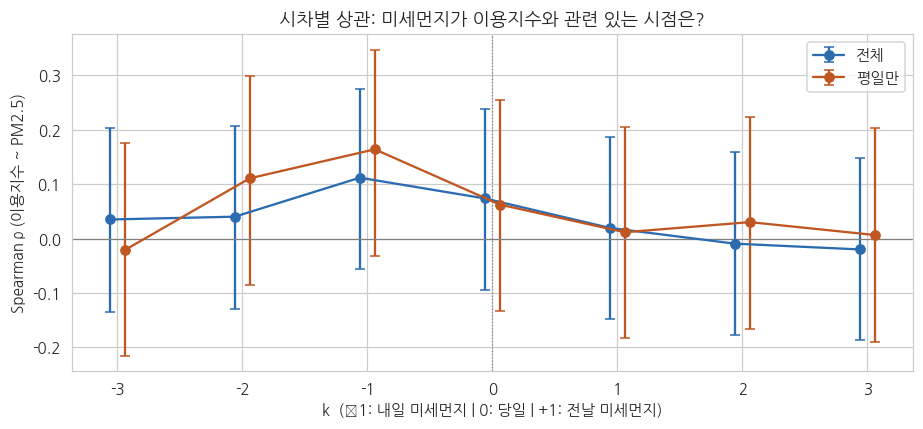

In [13]:
def lag_corr(frame, lags=range(-3, 4), dust_col="PM25"):
    out = []
    for k in lags:
        z = pd.DataFrame({"idx": frame["이용지수"], "p": df[dust_col].shift(k)}).dropna()
        rho, p = stats.spearmanr(z["p"], z["idx"])
        n = len(z)
        se = 1.06 / np.sqrt(n - 3)
        lo, hi = np.tanh(np.arctanh(rho) - 1.96 * se), np.tanh(np.arctanh(rho) + 1.96 * se)
        out.append({"k": k, "n": n, "rho": rho, "p": p, "lo": lo, "hi": hi})
    return pd.DataFrame(out).set_index("k")

lag_all  = lag_corr(an)
lag_wkdy = lag_corr(an[an["요일"] <= 4])
display(pd.concat({"전체(연휴 제외)": lag_all[["n", "rho", "p"]], "평일(월~금)": lag_wkdy[["n", "rho", "p"]]}, axis=1).round(3))

fig, ax = plt.subplots(figsize=(8.5, 4))
for lag, lab, c, off in [(lag_all, "전체", "#2b6cb0", -0.06), (lag_wkdy, "평일만", "#c05621", 0.06)]:
    ax.errorbar(lag.index + off, lag["rho"], yerr=[lag["rho"] - lag["lo"], lag["hi"] - lag["rho"]], fmt="o-", capsize=3, label=lab, color=c)
ax.axhline(0, color="gray", lw=0.8)
ax.axvline(0, color="gray", ls=":", lw=0.8)
ax.set_xlabel("k  (−1: 내일 미세먼지 | 0: 당일 | +1: 전날 미세먼지)")
ax.set_ylabel("Spearman ρ (이용지수 ~ PM2.5)")
ax.set_title("시차별 상관: 미세먼지가 이용지수와 관련 있는 시점은?")
ax.legend()
plt.tight_layout()
plt.show()


In [14]:
print("PM2.5 하루 자기상관:", round(df["PM25"].autocorr(1), 2))
try:
    import statsmodels.formula.api as smf
    z = an[an["요일"] <= 4].copy()
    z["PM25_당일"], z["PM25_전날"] = z["PM25"], df["PM25"].shift(1).reindex(z.index)
    fit2 = smf.ols("이용지수 ~ PM25_당일 + PM25_전날", data=z.dropna(subset=["PM25_전날"])).fit(cov_type="HC3")
    display(fit2.summary2().tables[1].round(5))
except ImportError:
    pass


PM2.5 하루 자기상관: 0.73


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,0.99913,0.00232,430.61111,0.00000,0.99458,1.00368
PM25_당일,0.00004,0.00009,0.40327,0.68675,-0.00014,0.00021
PM25_전날,-0.00005,0.00007,-0.69541,0.48680,-0.00019,0.00009


미세먼지 '나쁨' 시작일 18번: ['01-04', '01-07', '01-11', '01-18', '01-23', '02-12', '02-16', '02-20', '02-27', '03-11', '03-19', '03-27', '04-22', '05-04', '05-11', '05-15', '05-23', '06-05']


,n,이용지수 중앙값-1 (%),Wilcoxon p,Bonferroni 보정 p
시점,,,,
D-1,17,-0.03,0.782,1.000
D+0,17,0.87,0.027,0.108
D+1,15,0.04,0.804,1.000
D+2,15,-0.48,0.639,1.000


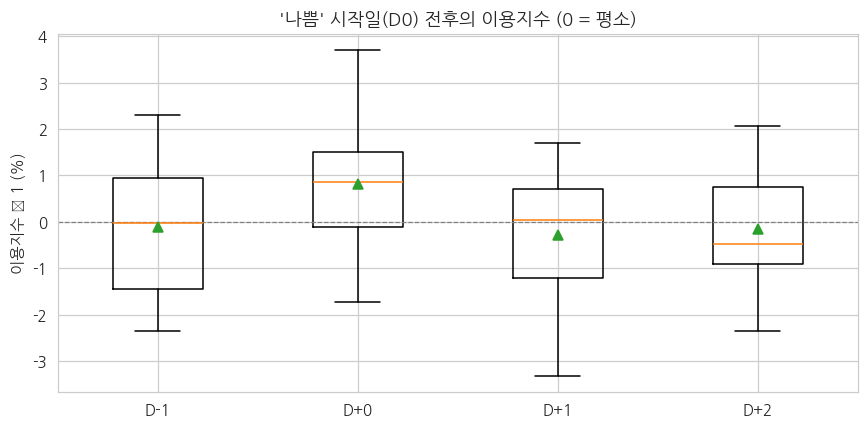

In [15]:
bad = df["PM25나쁨"]
onset = df.index[bad & ~bad.shift(1, fill_value=False)]
print(f"미세먼지 '나쁨' 시작일 {len(onset)}번:", [d.strftime("%m-%d") for d in onset])

rows, store = [], {}
for k in [-1, 0, 1, 2]:
    idx = [d + pd.Timedelta(days=k) for d in onset]
    v = df["이용지수"].reindex(idx).dropna()
    store[k] = v - 1
    rows.append({"시점": f"D{k:+d}", "n": len(v), "이용지수 중앙값-1 (%)": round((v.median() - 1) * 100, 2),
                 "Wilcoxon p": round(stats.wilcoxon(v - 1).pvalue, 3)})
ev = pd.DataFrame(rows).set_index("시점")
ev["Bonferroni 보정 p"] = (ev["Wilcoxon p"] * len(ev)).clip(upper=1).round(3)
display(ev)

fig, ax = plt.subplots(figsize=(8, 4))
labels = [f"D{k:+d}" for k in store]
data = [store[k] * 100 for k in store]
try:
    ax.boxplot(data, tick_labels=labels, showmeans=True)
except TypeError:
    ax.boxplot(data, labels=labels, showmeans=True)
ax.axhline(0, color="gray", ls="--", lw=0.8)
ax.set_ylabel("이용지수 − 1 (%)")
ax.set_title("'나쁨' 시작일(D0) 전후의 이용지수 (0 = 평소)")
plt.tight_layout()
plt.show()


### 질문 2 해석

**결론: 미세먼지가 심해진 당일에도, 다음 날에도 이용객이 줄었다는 증거는 없습니다.**

- **시차 상관**: 모든 시차에서 p > 0.05였고 |ρ| ≤ 0.17로 매우 약합니다. 당일(k=0) ρ=0.07 (p=0.36), 전날 미세먼지→오늘 이용객(k=+1) ρ=0.02 (p=0.81).
- **기준선(placebo)**: 가장 큰 상관은 오히려 *내일* 미세먼지(k=−1, 전체 ρ=0.11 / 평일 ρ=0.16)입니다. 미래의 값은 원인이 될 수 없으므로, 이 정도 크기는 우연이나 날씨 같은 공통 요인이 만드는 '잡음 수준'으로 보는 게 맞고, 당일·전날 상관은 그보다도 작습니다.
- **동시 회귀**: 미세먼지는 어제와 오늘이 비슷해서(자기상관 0.73) 당일·전날을 함께 넣어 봤지만 둘 다 유의하지 않았습니다 (p = 0.69, 0.49).
- **이벤트 스터디**: '나쁨' 시작일(D0)의 이용지수는 오히려 평소보다 +0.87% 높았고 Wilcoxon p = 0.027이지만, 네 시점을 동시에 검정했으므로 Bonferroni 보정 p = 0.108로 유의하지 않습니다. D−1, D+1, D+2도 모두 평소 수준입니다. 
- 따라서 "당일 vs 다음 날 중 언제 변하나?"에 대한 답은 *"어느 쪽도 뚜렷한 변화가 없다"* 입니다. D0의 소폭 증가는 (검증하지 않은 추정이지만) 미세먼지가 막 심해지는 날은 비가 오지 않는 맑고 건조한 날이 많아 이동이 늘어난 날씨 효과일 수 있습니다. 이 데이터에는 날씨가 없어서 확인할 수 없습니다.

## 6. 결론

### 한 줄 요약
| 질문 | 결과 |
|---|---|
| 1. 금요일에는 미세먼지가 심해도 이용객이 줄지 않나? | 줄지 않았다 (+0.06%p, p=0.91). 단, 월~목도 줄지 않았고 금요일만 다르다는 증거는 없다 (D=−0.40%p, p=0.63) |
| 2. 당일 vs 다음 날? | 둘 다 감소 증거 없음 (시차 상관 전 구간 p>0.05, 당일 이벤트는 보정 후 비유의) |

### 해석할 때 주의할 점
- **"효과 없음"이 아니라 "효과를 찾지 못함"**: 금요일 '나쁨'은 6일, 이벤트 스터디는 15~17건이라 표본이 작습니다. 약 1~1.5% 이하의 작은 변화는 이 데이터로 구분하기 어렵습니다.
- **날씨 교란**: 비·기온은 미세먼지와 이용객에 모두 영향을 주지만 데이터에 없습니다.
- **총량의 한계**: 하루 전체 승하차 합계라서 출퇴근 vs 나들이, 시간대별 변화, 마스크 착용 같은 행동 변화는 보이지 않습니다. 또 지하철은 수도권 전체(경기·인천 포함)인데 미세먼지는 서울 평균입니다.
- **연휴 처리·기준선 선택**: 연휴 구간과 '앞뒤 2주 중앙값' 기준선은 분석자가 정한 것입니다 (연휴 구간 포함 여부를 바꿔서 다시 돌려보는 것을 권장).
- **여러 번 검정**: 많이 검정할수록 우연히 p<0.05가 나올 수 있습니다 (D0 사례처럼).

### 최종 결론
- 미세먼지 '나쁨'인 금요일의 이용객은 그렇지 않은 금요일과 유의한 차이가 없었다 (Mann-Whitney U, p=0.91).
- 월~목과 금요일의 미세먼지 반응 차이도 유의하지 않았다 (순열검정, p=0.63).
- 미세먼지 악화 당일·다음 날 모두 이용객 감소는 관찰되지 않았다 (Wilcoxon 부호순위검정, Bonferroni 보정 후 p>0.05).